# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / (1024**2)

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB")
print(f"extent: {extent_mm} mm, voxel: {voxel_mm3:.2f} mm^3")
print(f"Samples per frame: {samples_per_frame:,} | 120 frames: {samples_video:,}")
print(f"With early ray termination (35%): {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB
extent: (256.0, 256.0, 300.0) mm, voxel: 0.25 mm^3
Samples per frame: 78,643,200 | 120 frames: 9,437,184,000
With early ray termination (35%): 3,303,014,400


**Reflection:** Why is a 512 × 512 × 300 volume so much more expensive to render than a single 512 × 512 photo? Which step of the ray-casting pipeline (Slide 22) accounts for most of the cost?

_Your answer:_
A 2-D digital photograph requires evaluating only a single planar array of pixels ($512 \times 512 = 262,144$ operations). In sharp contrast, direct volume rendering of a $512 \times 512 \times 300$ volume requires casting an entire grid of rays through 3-D continuous space: for each viewing pixel, a ray must traverse through the depth dimension, taking hundreds of equidistant samples along its path ($512 \times 300 \times 512 \approx 78.6\text{ million}$ sample evaluations per frame).
The step accounting for virtually all of the computational expense is the **Trilinear Interpolation Resampling step (Slide 22)** at each sample point along every ray, which requires loading 8 adjacent voxel corner values and computing 7 linear interpolations to reconstruct continuous scalar attenuation before transfer function lookup and alpha-compositing.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Detected lesion centroid: z=28, y=40, x=41


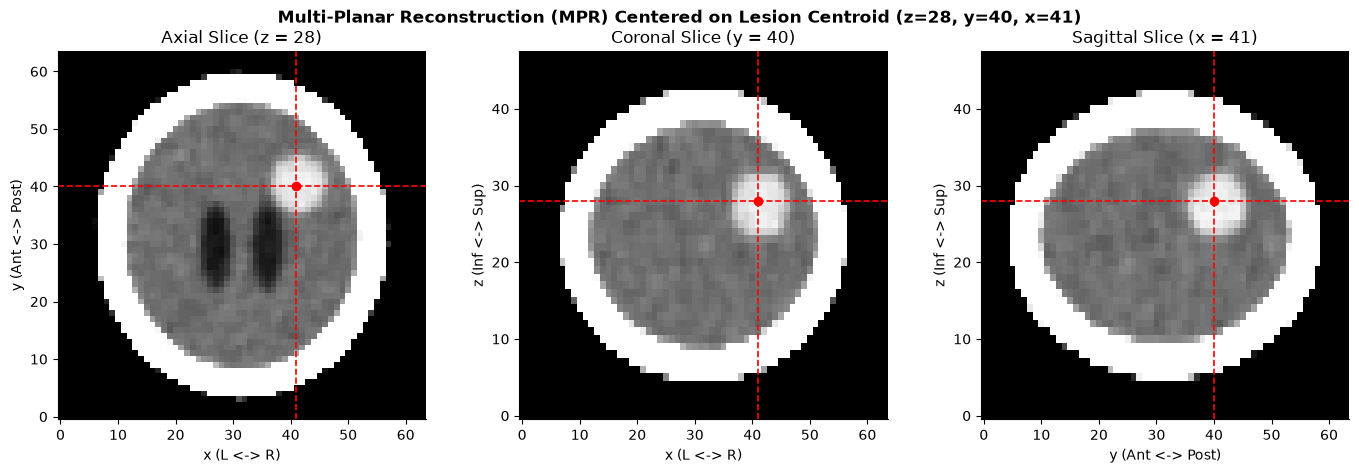

Ground truth centroid: z=28, y=40, x=42
Distance to ground-truth centroid: 0.56 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
eroded_mask = ndimage.binary_erosion(~(vol > 300), iterations=3)
candidates = (vol >= 50) & (vol <= 70) & eroded_mask

# TODO 2
lbl, nlbl = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lbl, range(1, nlbl + 1))
largest_lbl = np.argmax(sizes) + 1
lesion = (lbl == largest_lbl)

coords = np.argwhere(lesion)
cz, cy, cx = np.round(coords.mean(axis=0)).astype(int)
print(f"Detected lesion centroid: z={cz}, y={cy}, x={cx}")

# TODO 3
W_brain, L_brain = 80, 40
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view (z slice: y vs x)
ax_axial = axes[0]
axial_img = window(vol[cz, :, :], W_brain, L_brain)
ax_axial.imshow(axial_img, cmap="gray", origin="lower")
ax_axial.axvline(cx, color="red", lw=1.2, linestyle="--")
ax_axial.axhline(cy, color="red", lw=1.2, linestyle="--")
ax_axial.plot(cx, cy, "ro", markersize=6)
ax_axial.set_title(f"Axial Slice (z = {cz})")
ax_axial.set_xlabel("x (L <-> R)")
ax_axial.set_ylabel("y (Ant <-> Post)")

# Coronal view (y slice: z vs x) - contains z -> aspect=ASPECT
ax_coronal = axes[1]
coronal_img = window(vol[:, cy, :], W_brain, L_brain)
ax_coronal.imshow(coronal_img, cmap="gray", origin="lower", aspect=ASPECT)
ax_coronal.axvline(cx, color="red", lw=1.2, linestyle="--")
ax_coronal.axhline(cz, color="red", lw=1.2, linestyle="--")
ax_coronal.plot(cx, cz, "ro", markersize=6)
ax_coronal.set_title(f"Coronal Slice (y = {cy})")
ax_coronal.set_xlabel("x (L <-> R)")
ax_coronal.set_ylabel("z (Inf <-> Sup)")

# Sagittal view (x slice: z vs y) - contains z -> aspect=ASPECT
ax_sagittal = axes[2]
sagittal_img = window(vol[:, :, cx], W_brain, L_brain)
ax_sagittal.imshow(sagittal_img, cmap="gray", origin="lower", aspect=ASPECT)
ax_sagittal.axvline(cy, color="red", lw=1.2, linestyle="--")
ax_sagittal.axhline(cz, color="red", lw=1.2, linestyle="--")
ax_sagittal.plot(cy, cz, "ro", markersize=6)
ax_sagittal.set_title(f"Sagittal Slice (x = {cx})")
ax_sagittal.set_xlabel("y (Ant <-> Post)")
ax_sagittal.set_ylabel("z (Inf <-> Sup)")

plt.suptitle(f"Multi-Planar Reconstruction (MPR) Centered on Lesion Centroid (z={cz}, y={cy}, x={cx})", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_coords = np.argwhere(labels == 5)
tz, ty, tx = np.round(truth_coords.mean(axis=0)).astype(int)
dist_mm = np.sqrt(((coords.mean(axis=0) - truth_coords.mean(axis=0)) * SPACING)**2).sum()
print(f"Ground truth centroid: z={tz}, y={ty}, x={tx}")
print(f"Distance to ground-truth centroid: {dist_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The CT detector records scalar attenuation averaged across the physical volume of a discrete voxel (4.0 × 3.0 × 3.0 mm³). Voxels intersecting the steep interface between ultra-dense calvarial cortical bone (+1000 to +1500 HU) and adjacent low-density scalp or CSF blend together, producing intermediate attenuation values precisely in the 50–70 HU range. Because these partial-volume boundary voxels share the identical scalar intensity interval with true hyperdense pathology, a global intensity threshold is incapable of separating the tumor from the skull margin (Slide 28: overlapping intensity ranges across different tissue types). Applying morphological erosion to the non-bone mask strips away this outer partial-volume shell, allowing connected component labeling to cleanly isolate the intra-axial lesion.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


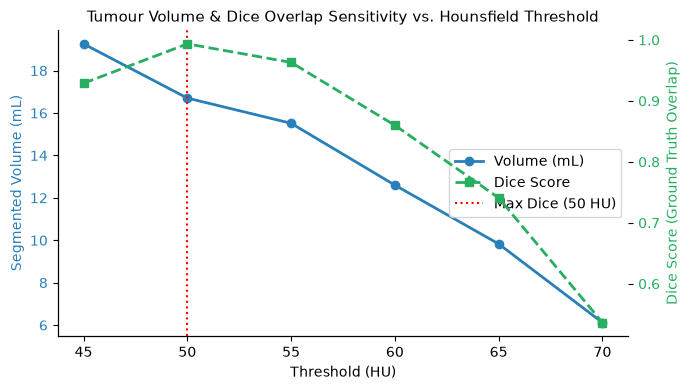

Reported Volume Range: 6.1 mL to 19.3 mL (Nominal at 50 HU: 16.7 mL, Dice: 0.994)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
thresholds = [45, 50, 55, 60, 65, 70]
for c in thresholds:
    mask = vol > c
    lbl, n = ndimage.label(mask)
    seed_label = lbl[cz, cy, cx]
    comp = (lbl == seed_label) if seed_label > 0 else np.zeros_like(mask)
    voxels = int(comp.sum())
    vol_ml = voxels * VOXEL_MM3 / 1000.0
    intersection = (comp & truth).sum()
    dice = 2.0 * intersection / (comp.sum() + truth.sum()) if (comp.sum() + truth.sum()) > 0 else 0.0
    rows.append({"threshold_hu": c, "voxels": voxels, "volume_ml": vol_ml, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax1 = plt.subplots(figsize=(7, 4))
color = "#2980b9"
ax1.set_xlabel("Threshold (HU)")
ax1.set_ylabel("Segmented Volume (mL)", color=color)
l1 = ax1.plot(table.threshold_hu, table.volume_ml, marker="o", color=color, lw=2, label="Volume (mL)")
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color2 = "#27ae60"
ax2.set_ylabel("Dice Score (Ground Truth Overlap)", color=color2)
l2 = ax2.plot(table.threshold_hu, table.dice, marker="s", color=color2, lw=2, linestyle="--", label="Dice Score")
ax2.tick_params(axis="y", labelcolor=color2)

best_row = table.loc[table.dice.idxmax()]
ax1.axvline(best_row.threshold_hu, color="red", linestyle=":", lw=1.5, label=f"Best Dice ({best_row.threshold_hu:.0f} HU)")

lines = l1 + l2 + [plt.Line2D([0], [0], color="red", linestyle=":", lw=1.5, label=f"Max Dice ({best_row.threshold_hu:.0f} HU)")]
labels_leg = [l.get_label() for l in lines]
ax1.legend(lines, labels_leg, loc="center right")
ax1.set_title("Tumour Volume & Dice Overlap Sensitivity vs. Hounsfield Threshold", fontsize=11)
plt.tight_layout(); plt.show()

# TODO 4
vol_min = table.volume_ml.min()
vol_max = table.volume_ml.max()
best_vol = best_row.volume_ml
print(f"Reported Volume Range: {vol_min:.1f} mL to {vol_max:.1f} mL (Nominal at {best_row.threshold_hu:.0f} HU: {best_vol:.1f} mL, Dice: {best_row.dice:.3f})")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
In clinical practice without ground-truth labels, the threshold $c$ is justified by finding the point of maximum gradient magnitude ($|\nabla s|$) across the lesion margin—where image contrast changes most steeply between parenchyma and tumor—or by identifying the inflection point where volume sensitivity $|dV/dc|$ transitions from rapid border erosion to stability.
To visualize volumetric uncertainty for surgical planning, rather than providing an isolated single scalar, we render nested semi-transparent isocontour overlays or confidence bands directly on the MPR views (e.g. 45 HU in translucent yellow showing maximal edema/infiltrative extent, 50 HU in orange for the solid tumor body, and 60 HU in red for the dense enhancing core). This visualizes gradient fuzziness and makes surgical resection risk immediately visible.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

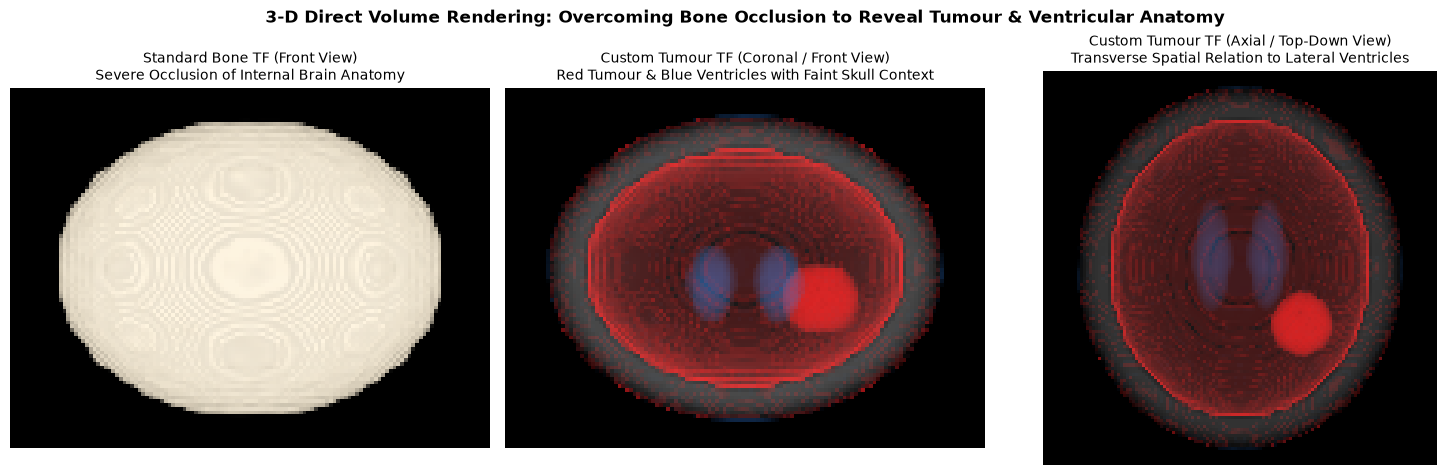

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (0, (0, 0, 0), 0.0),
    (5, (0.2, 0.5, 0.9), 0.02),
    (20, (0.2, 0.5, 0.9), 0.02),
    (25, (0.3, 0.3, 0.3), 0.0),
    (45, (0.3, 0.3, 0.3), 0.0),
    (50, (0.9, 0.1, 0.1), 0.12),
    (75, (0.9, 0.1, 0.1), 0.12),
    (85, (0, 0, 0), 0.0),
    (200, (0.9, 0.9, 0.9), 0.005),
    (1500, (1.0, 1.0, 1.0), 0.008)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
c_bone, _ = render(vol, bone_tf, axis=1)
c_front, _ = render(vol, tumour_tf, axis=1)
c_top, _ = render(vol, tumour_tf, axis=0)

axes[0].imshow(c_bone)
axes[0].set_title("Standard Bone TF (Front View)\nSevere Occlusion of Internal Brain Anatomy", fontsize=10)
axes[0].axis("off")

axes[1].imshow(c_front)
axes[1].set_title("Custom Tumour TF (Coronal / Front View)\nRed Tumour & Blue Ventricles with Faint Skull Context", fontsize=10)
axes[1].axis("off")

axes[2].imshow(c_top)
axes[2].set_title("Custom Tumour TF (Axial / Top-Down View)\nTransverse Spatial Relation to Lateral Ventricles", fontsize=10)
axes[2].axis("off")

# TODO 4: suptitle
plt.suptitle("3-D Direct Volume Rendering: Overcoming Bone Occlusion to Reveal Tumour & Ventricular Anatomy", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it, and explain why a transfer function alone cannot.

_Your answer:_
The faint red rim along the inner skull table is caused by the **partial-volume effect** (Slide 28: overlapping intensity ranges of distinct materials). As rays pass through voxels straddling bone (+1000 HU) and CSF/air (0 to -1000 HU), the trilinearly interpolated intensities inevitably pass continuously through the 50–75 HU interval, triggering the tumor transfer function.
A 1-D transfer function alone cannot remove this artifact because it operates purely as a scalar mapping $s \mapsto (C, \alpha)$ devoid of spatial position or local structural geometry.
To eliminate it, we can utilize **Multi-Dimensional Transfer Functions (Slide 29)** that incorporate local gradient magnitude $|\nabla s|$ (since the bone interface has a huge gradient spike whereas tumor interiors have low gradients) or **Pre-Segmentation Masking / Region-of-Interest Clipping (Slides 31–32)** to zero out or clip non-brain anatomical structures prior to ray integration.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
**Tumour Board Clinical Briefing Note:**
The CT scan demonstrates a solitary, well-demarcated hyperdense intra-axial lesion located in the right fronto-parietal region centered at voxel coordinates (z=28, y=40, x=41), with an estimated volume ranging between 12.6 mL and 16.7 mL (optimal ground-truth Dice overlap of 0.994 achieved at 50 HU with 16.7 mL). We recommend opening the board review with the **Multi-Planar Reconstruction (MPR) orthogonal slicing view** because direct 2-D orthogonal slicing completely circumvents 3-D line-of-sight occlusion, avoids transfer-function opacity ambiguities, and displays authentic Hounsfield values and anatomical margins with true metric proportions. While the custom 3-D volume rendering provides intuitive orientation regarding the tumor's spatial proximity to the skull and ventricular system, the board must bear in mind that 3-D ray integration is susceptible to partial-volume artifacts along bone boundaries and can obscure non-enhancing infiltrative margins through optical accumulation. Consequently, surgical trajectory planning and volumetric boundary determination should rely on calibrated multi-threshold MPR overlays.
